In [1]:
import matplotlib.pyplot as plt
from keras.datasets import imdb
from keras.utils import pad_sequences
from keras.models import Sequential
from keras.layers import Embedding, SimpleRNN, LSTM, Dense, Bidirectional

In [2]:
max_features = 10000
maxlen = 500
batch_size = 128
epochs = 5

In [3]:
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=max_features)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [4]:
x_train = pad_sequences(x_train, maxlen=maxlen)
x_test = pad_sequences(x_test, maxlen=maxlen)
print(f"Розмірність тренувальних даних: {x_train.shape}")
print(f"Розмірність тестових даних: {x_test.shape}")

Розмірність тренувальних даних: (25000, 500)
Розмірність тестових даних: (25000, 500)


In [5]:
model_rnn = Sequential([
    Embedding(max_features, 32),
    SimpleRNN(32),
    Dense(1, activation='sigmoid')
])

In [6]:
model_rnn.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['acc'])
print("Навчання SimpleRNN")
history_rnn = model_rnn.fit(x_train, y_train, epochs=epochs, batch_size=batch_size, validation_split=0.3)

Навчання SimpleRNN
Epoch 1/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 47s 283ms/step - acc: 0.6593 - loss: 0.6081 - val_acc: 0.7971 - val_loss: 0.4745
Epoch 2/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - acc: 0.8205 - loss: 0.4132 - val_acc: 0.8423 - val_loss: 0.3793
Epoch 3/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 11s 83ms/step - acc: 0.8511 - loss: 0.3501 - val_acc: 0.8407 - val_loss: 0.3741
Epoch 4/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 12s 88ms/step - acc: 0.8747 - loss: 0.3034 - val_acc: 0.8423 - val_loss: 0.3663
Epoch 5/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 17s 128ms/step - acc: 0.8954 - loss: 0.2577 - val_acc: 0.8519 - val_loss: 0.3804


In [7]:
model_lstm = Sequential([
    Embedding(max_features, 32),
    LSTM(32),
    Dense(1, activation='sigmoid')
])

model_lstm.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['acc'])
print("Навчання LSTM")
history_lstm = model_lstm.fit(x_train, y_train, epochs=epochs, batch_size=batch_size, validation_split=0.3)

Навчання LSTM
Epoch 1/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - acc: 0.6270 - loss: 0.6338 - val_acc: 0.7775 - val_loss: 0.4898
Epoch 2/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - acc: 0.8095 - loss: 0.4338 - val_acc: 0.8429 - val_loss: 0.3705
Epoch 3/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - acc: 0.8590 - loss: 0.3422 - val_acc: 0.8261 - val_loss: 0.4042
Epoch 4/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - acc: 0.8739 - loss: 0.3114 - val_acc: 0.7252 - val_loss: 0.7472
Epoch 5/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - acc: 0.8831 - loss: 0.2896 - val_acc: 0.8619 - val_loss: 0.3445


In [8]:
model_bidir = Sequential([
    Embedding(max_features, 32),
    Bidirectional(LSTM(32)),
    Dense(1, activation='sigmoid')
])

model_bidir.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['acc'])
print("Навчання Bidirectional LSTM")
history_bidir = model_bidir.fit(x_train, y_train, epochs=epochs, batch_size=batch_size, validation_split=0.3)

Навчання Bidirectional LSTM
Epoch 1/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 8s 43ms/step - acc: 0.6105 - loss: 0.6489 - val_acc: 0.7633 - val_loss: 0.5068
Epoch 2/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - acc: 0.8032 - loss: 0.4405 - val_acc: 0.8249 - val_loss: 0.4070
Epoch 3/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - acc: 0.8491 - loss: 0.3611 - val_acc: 0.8353 - val_loss: 0.3774
Epoch 4/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - acc: 0.8724 - loss: 0.3143 - val_acc: 0.8127 - val_loss: 0.4362
Epoch 5/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - acc: 0.8812 - loss: 0.2938 - val_acc: 0.8573 - val_loss: 0.3396


In [9]:
model_deep = Sequential([
    Embedding(max_features, 32),
    LSTM(32, return_sequences=True),
    LSTM(32),
    Dense(1, activation='sigmoid')
])

model_deep.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['acc'])
print("Навчання Deep LSTM")
history_deep = model_deep.fit(x_train, y_train, epochs=epochs, batch_size=batch_size, validation_split=0.3)

Навчання Deep LSTM
Epoch 1/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - acc: 0.6355 - loss: 0.6137 - val_acc: 0.7171 - val_loss: 0.5383
Epoch 2/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - acc: 0.8131 - loss: 0.4255 - val_acc: 0.7889 - val_loss: 0.4518
Epoch 3/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - acc: 0.8526 - loss: 0.3571 - val_acc: 0.8724 - val_loss: 0.3102
Epoch 4/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - acc: 0.8762 - loss: 0.3095 - val_acc: 0.8792 - val_loss: 0.2985
Epoch 5/5
137/137 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - acc: 0.8926 - loss: 0.2737 - val_acc: 0.8715 - val_loss: 0.3078


In [10]:
loss_rnn, acc_rnn = model_rnn.evaluate(x_test, y_test, verbose=0)
loss_lstm, acc_lstm = model_lstm.evaluate(x_test, y_test, verbose=0)
loss_bidir, acc_bidir = model_bidir.evaluate(x_test, y_test, verbose=0)
loss_deep, acc_deep = model_deep.evaluate(x_test, y_test, verbose=0)

print(f"SimpleRNN Точність: {acc_rnn:.4f}")
print(f"LSTM Точність: {acc_lstm:.4f}")
print(f"Bidirectional Точність: {acc_bidir:.4f}")
print(f"Deep LSTM Точність: {acc_deep:.4f}")

SimpleRNN Точність: 0.8496
LSTM Точність: 0.8582
Bidirectional Точність: 0.8558
Deep LSTM Точність: 0.8706


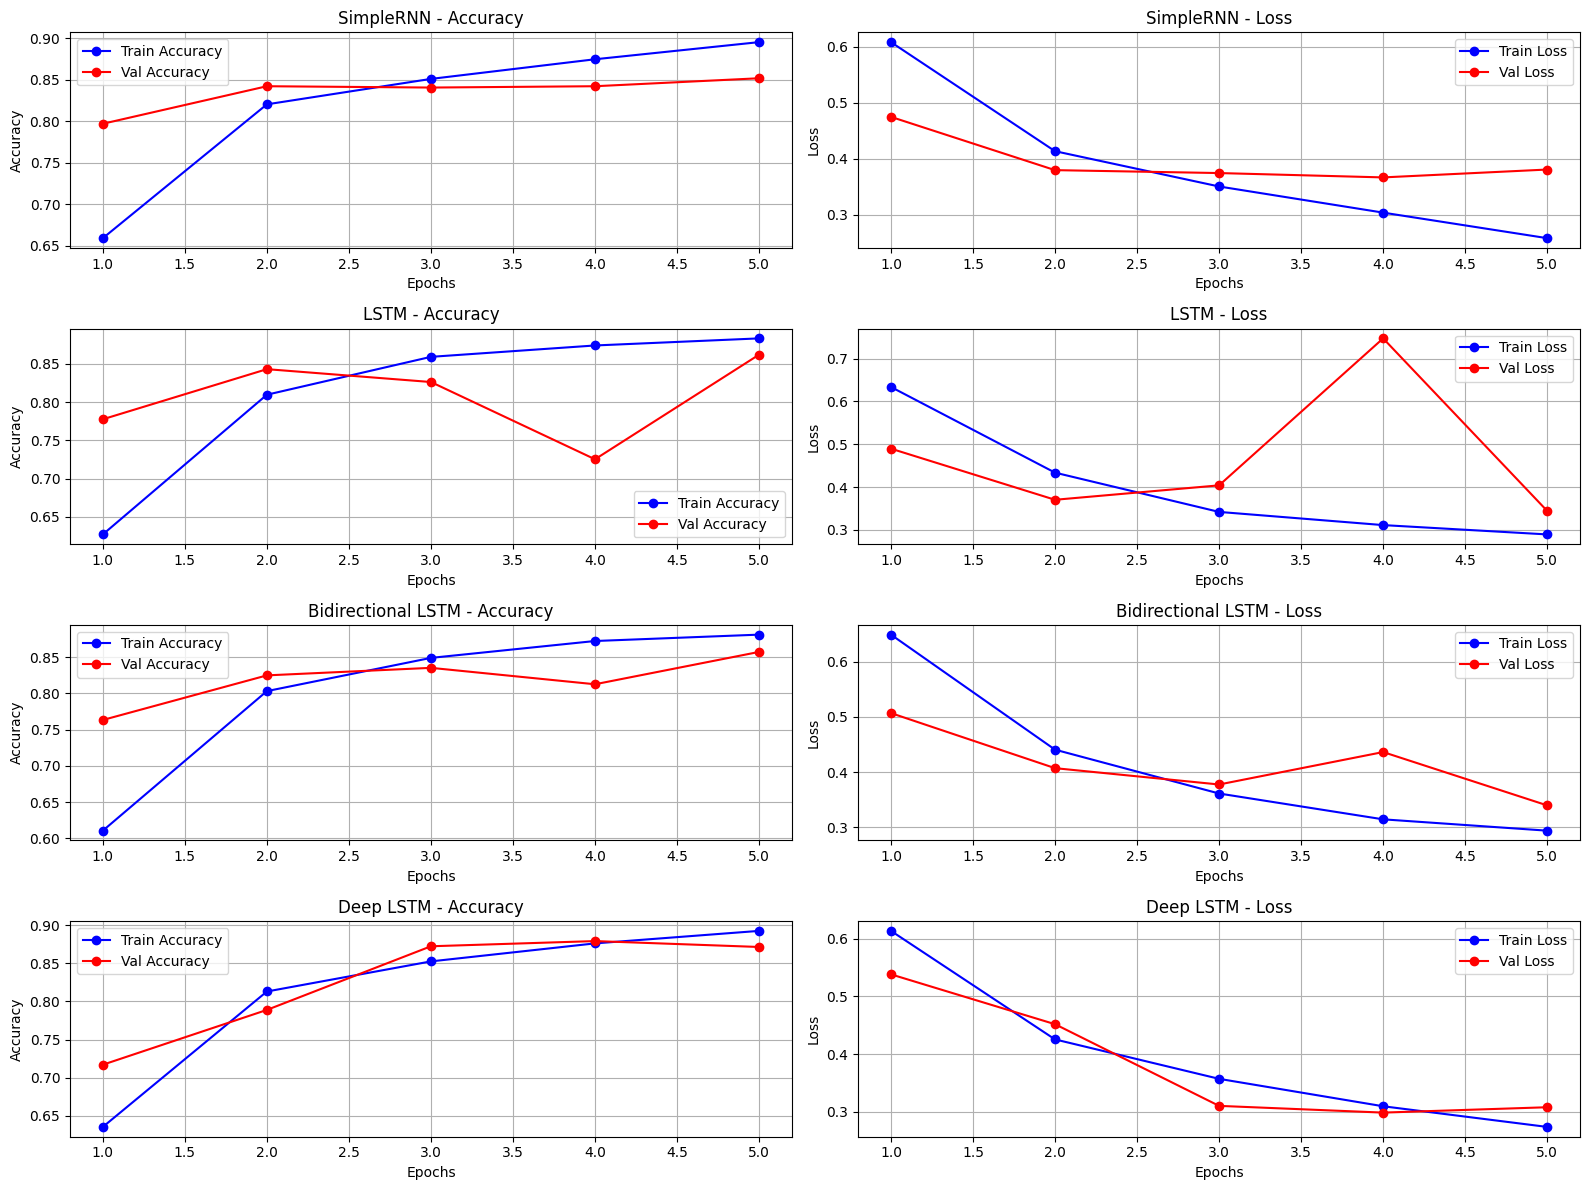

In [11]:
import matplotlib.pyplot as plt

histories = {
    "SimpleRNN": history_rnn,
    "LSTM": history_lstm,
    "Bidirectional LSTM": history_bidir,
    "Deep LSTM": history_deep
}

plt.figure(figsize=(16, 12))

for i, (name, history) in enumerate(histories.items(), 1):
    epochs_range = range(1, len(history.history['acc']) + 1)

    plt.subplot(4, 2, 2 * i - 1)
    plt.plot(epochs_range, history.history['acc'], 'bo-', label='Train Accuracy')
    plt.plot(epochs_range, history.history['val_acc'], 'ro-', label='Val Accuracy')
    plt.title(f'{name} - Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.subplot(4, 2, 2 * i)
    plt.plot(epochs_range, history.history['loss'], 'bo-', label='Train Loss')
    plt.plot(epochs_range, history.history['val_loss'], 'ro-', label='Val Loss')
    plt.title(f'{name} - Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

Для задачі класифікації відгуків IMDb найоптимальнішим вибором виявилася архітектура Deep LSTM, яка досягла найвищої точності на тестових даних (87.06%). Нарощування глибини мережі (використання двох послідовних шарів LSTM) дозволило краще вловити складні контекстні залежності в тексті порівняно з одношаровими моделями.